# Contouring

In [1]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
from figs_to_html import figs_to_html

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-paper')

In [2]:
import src.Retrieval as retrieval
from src.ExperimentSet import ExperimentSet
from src.utils.util import set_labels

In [3]:
def get_pixels(r, i, mask_name='ray_containment', mask_vals=[0,1,2]):
    misr = r.obs['MISR']['sensor_list'][i]
    at3d = r.sensors_retrieval['MISR']['sensor_list'][i]
    mask = np.isin(r.masks['MISR']['sensor_list'][i][mask_name].data, mask_vals)
    x = misr.ray_x.data[mask]
    y = misr.ray_y.data[mask]
    m = misr.brf.data[mask]
    a = at3d.brf.data[mask]
    return misr, at3d, mask, x, y, m, a

def plot_F_vs_MISR_single_cam(f, ax, r, mask_name, mask_vals, plot_kwargs, diff_kwargs, contr_kwargs, i=0, contr=True, dom_boarder=False, correction=0, text_y=22):
    (misr, at3d, mask, x, y, m, a) = get_pixels(r, i, mask_name, mask_vals)
    a = a-correction
    ax[0].tricontourf(x, y, m, **plot_kwargs)
    c1 = ax[1].tricontourf(x, y, a, **plot_kwargs)
    c2 = ax[2].tricontourf(x, y, a-m, **diff_kwargs)
    # c2 = ax[2].tricontourf(x, y, 100*(a-m)/m, **diff_kwargs)
    if(contr):
        ax[0].tricontour(x, y, a-m, **contr_kwargs)
        ax[1].tricontour(x, y, a-m, **contr_kwargs)
        ax[2].tricontour(x, y, a-m, colors='k', levels=contr_kwargs['levels'])
    # ax[0].set_xlabel('x (km)')
    # ax[1].set_xlabel('x (km)')
    # ax[2].set_xlabel('x (km)')
    # plt.colorbar(c1, ax=ax[0:2, :], label='BRF', shrink=0.8, ticks=[0.0, 0.1, 0.2, 0.3, 0.4])
    # plt.colorbar(c2, ax=ax[2,:], label='BRF Difference', shrink=0.8, ticks=[diff_kwargs['vmin'], 0.0, diff_kwargs['vmax']])
    # lvls = contr_kwargs['levels']
    # ax[0].text(0, text_y, f'{misr.name} | contr:{str(lvls)} | {str(r)}')
    # ax[0].set_title('MISR')
    # if(correction != 0.0):
    #     ax[1].set_title(f'AT3D - {correction}')
    #     ax[2].set_title(f'AT3D - {correction} - MISR')
    # else:
    #     ax[1].set_title('AT3D')
    #     ax[2].set_title('AT3D - MISR')
    # ax[0].set_ylabel('y (km)')
    ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
    box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
    for a in ax.flat:
        if(dom_boarder):
            a.plot([0, 0], [0, 17.6], **box_kwargs)
            a.plot([0, 17.6], [0, 0], **box_kwargs)
            a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
            a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
        a.set_xticks(ticks)
        a.set_xticklabels(ticks, rotation=45)
        a.set_yticks(ticks)
    return c1, c2

In [4]:
version = 'V11'
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / version
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [5]:
vrange = 0.26
plot_kwargs = {
    'cmap':'gray',
    'vmin':0,
    'vmax':0.4,
    'levels':np.linspace(0, 0.4, 50)
}
diff_kwargs = {
    'cmap':'RdBu_r',
    'vmin':-vrange,
    'vmax':vrange,
    'levels':np.linspace(-vrange, vrange, 100)
}
contr_kwargs = diff_kwargs.copy()
contr_kwargs['levels'] = np.array([0.04])

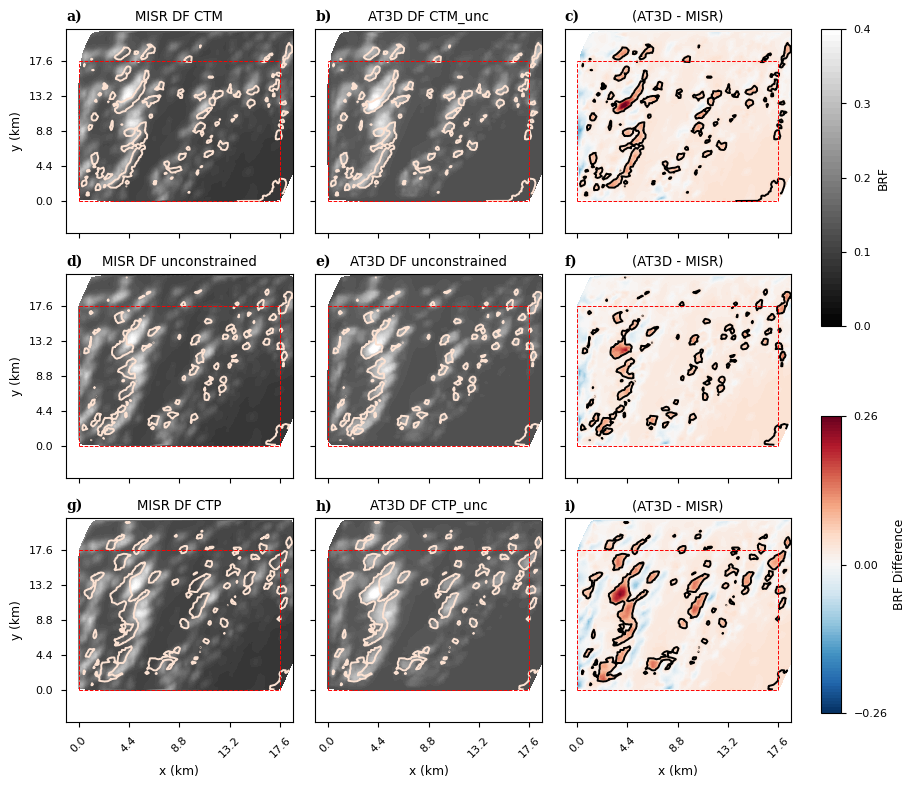

In [6]:
track = 'CT'
j = 0
pltlist_ex = [f'{track}M_unc', 'unconstrained', f'{track}P_unc']
pltlist_cam = [j]* len(pltlist_ex)
pltlist_contr = [0.04] * len(pltlist_cam)

f, ax = plt.subplots(len(pltlist_cam), 3, figsize=(10, 3*len(pltlist_cam)), sharex=True, sharey=True)
f.subplots_adjust(wspace=0.1, hspace=0.2, right=0.85)
for i, (ex, cam, contr) in enumerate(zip(pltlist_ex, pltlist_cam, pltlist_contr)):
    contr_kwargs['levels'] = np.array([contr])
    c1, c2 = plot_F_vs_MISR_single_cam(
        f,
        ax[i,:],
        exset.get_retrieval(ex),
        'ray_containment',
        [0,1,2],
        plot_kwargs,
        diff_kwargs,
        contr_kwargs,
        i=cam,
        contr=True,
        dom_boarder=True,
        correction=0.0,
        text_y=22
    )
for a in ax.flatten():
    a.set_xlim([-1.1, 18.7])
    a.set_ylim([-4.0, 21.6])
set_labels(ax.flatten())

ax[0,0].set_title(f'MISR DF {track}M')
ax[1,0].set_title('MISR DF unconstrained')
ax[2,0].set_title(f'MISR DF {track}P')
ax[0,1].set_title(f'AT3D DF {track}M_unc')
ax[1,1].set_title('AT3D DF unconstrained')
ax[2,1].set_title(f'AT3D DF {track}P_unc')
ax[0,2].set_title('(AT3D - MISR)')
ax[1,2].set_title('(AT3D - MISR)')
ax[2,2].set_title('(AT3D - MISR)')

ax[0,0].set_ylabel('y (km)')
ax[1,0].set_ylabel('y (km)')
ax[2,0].set_ylabel('y (km)')
ax[2,0].set_xlabel('x (km)')
ax[2,1].set_xlabel('x (km)')
ax[2,2].set_xlabel('x (km)')

# Two stacked colorbars in the right margin
# [left, bottom, width, height] in figure-fraction coords
cax1 = f.add_axes([0.88, 0.55, 0.02, 0.33])  # top: BRF
cax2 = f.add_axes([0.88, 0.12, 0.02, 0.33])  # bottom: difference

f.colorbar(c1, cax=cax1, label='BRF',
           ticks=[0.0, 0.1, 0.2, 0.3, 0.4])
f.colorbar(c2, cax=cax2, label='BRF Difference',
           ticks=[diff_kwargs['vmin'], 0.0, diff_kwargs['vmax']])

# # One shared colorbar for the BRF panels (columns 0 and 1, all rows)
# f.colorbar(c1, ax=ax[:, 0:2], label='BRF', shrink=0.8,
#            ticks=[0.0, 0.1, 0.2, 0.3, 0.4])

# # One shared colorbar for the difference panels (column 2, all rows)
# f.colorbar(c2, ax=ax[:, 2], label='BRF Difference', shrink=0.8,
#            ticks=[diff_kwargs['vmin'], 0.0, diff_kwargs['vmax']])
# plt.close(f)
# figs_to_html(figlist, es_dir / f'{version}_{track}_unc.html')

# Prominent bright feature

In [ ]:
pltlist_ex = ['default', 'unconstrained', 'periodic'] * 2
pltlist_cam = [0,0,0,8,8,8]
pltlist_contr = [0.04] * len(pltlist_cam)

f, ax = plt.subplots(len(pltlist_cam), 3, figsize=(10, 3*len(pltlist_cam)), sharex=True, sharey=True)
for i, (ex, cam, contr) in enumerate(zip(pltlist_ex, pltlist_cam, pltlist_contr)):
    contr_kwargs['levels'] = np.array([contr])
    plot_F_vs_MISR_single_cam(
        f,
        ax[i,:],
        exset.get_retrieval(ex),
        'ray_containment',
        [0,1,2],
        plot_kwargs,
        diff_kwargs,
        contr_kwargs,
        i=cam,
        contr=True,
        dom_boarder=True,
        correction=0.0,
        text_y=22
    )

# Uniform bright component

In [ ]:
pltlist_ex = ['default'] * 4
pltlist_cam = [0] * 4
pltlist_contr = [0.02, 0.03, 0.04, 0.05]

f, ax = plt.subplots(len(pltlist_cam), 3, figsize=(10, 3*len(pltlist_cam)), sharex=True, sharey=True)
for i, (ex, cam, contr) in enumerate(zip(pltlist_ex, pltlist_cam, pltlist_contr)):
    contr_kwargs['levels'] = np.array([contr])
    plot_F_vs_MISR_single_cam(
        f,
        ax[i,:],
        exset.get_retrieval(ex),
        'ray_containment',
        [0,1,2],
        plot_kwargs,
        diff_kwargs,
        contr_kwargs,
        i=cam,
        contr=True,
        dom_boarder=True,
        correction=0.0,
        text_y=22
    )

# AA View

In [ ]:
pltlist_ex = ['default'] * 4
pltlist_cam = [5] * 4
pltlist_contr = [0.0, -0.01, -0.02, -0.03]

f, ax = plt.subplots(len(pltlist_cam), 3, figsize=(10, 3*len(pltlist_cam)), sharex=True, sharey=True)
for i, (ex, cam, contr) in enumerate(zip(pltlist_ex, pltlist_cam, pltlist_contr)):
    contr_kwargs['levels'] = np.array([contr])
    plot_F_vs_MISR_single_cam(
        f,
        ax[i,:],
        exset.get_retrieval(ex),
        'ray_containment',
        [0,1,2],
        plot_kwargs,
        diff_kwargs,
        contr_kwargs,
        i=cam,
        contr=True,
        dom_boarder=True,
        correction=0.0,
        text_y=19
    )

# Cloud motion

## Along track all views

In [ ]:
track = 'AT'
figlist = []
for j in range(9):
    pltlist_ex = [f'{track}M', 'default', f'{track}P']
    pltlist_cam = [j]* len(pltlist_ex)
    pltlist_contr = [0.04] * len(pltlist_cam)

    f, ax = plt.subplots(len(pltlist_cam), 3, figsize=(10, 3*len(pltlist_cam)), sharex=True, sharey=True)
    for i, (ex, cam, contr) in enumerate(zip(pltlist_ex, pltlist_cam, pltlist_contr)):
        contr_kwargs['levels'] = np.array([contr])
        plot_F_vs_MISR_single_cam(
            f,
            ax[i,:],
            exset.get_retrieval(ex),
            'ray_containment',
            [0,1,2],
            plot_kwargs,
            diff_kwargs,
            contr_kwargs,
            i=cam,
            contr=True,
            dom_boarder=True,
            correction=0.0,
            text_y=22
        )
    for a in ax.flatten():
        a.set_xlim([-1.1, 18.7])
        a.set_ylim([-4.0, 21.6])
    figlist.append(f)
    plt.close(f)
figs_to_html(figlist, es_dir / f'{version}_{track}.html')

## Cross track all views

In [ ]:
track = 'CT'
figlist = []
for j in range(9):
    pltlist_ex = [f'{track}M', 'default', f'{track}P']
    pltlist_cam = [j]* len(pltlist_ex)
    pltlist_contr = [0.04] * len(pltlist_cam)

    f, ax = plt.subplots(len(pltlist_cam), 3, figsize=(10, 3*len(pltlist_cam)), sharex=True, sharey=True)
    for i, (ex, cam, contr) in enumerate(zip(pltlist_ex, pltlist_cam, pltlist_contr)):
        contr_kwargs['levels'] = np.array([contr])
        plot_F_vs_MISR_single_cam(
            f,
            ax[i,:],
            exset.get_retrieval(ex),
            'ray_containment',
            [0,1,2],
            plot_kwargs,
            diff_kwargs,
            contr_kwargs,
            i=cam,
            contr=True,
            dom_boarder=True,
            correction=0.0,
            text_y=22
        )
    for a in ax.flatten():
        a.set_xlim([-1.1, 18.7])
        a.set_ylim([-4.0, 21.6])
    figlist.append(f)
    plt.close(f)
figs_to_html(figlist, es_dir / f'{version}_{track}.html')

## Along track all views unconstrained

In [ ]:
track = 'AT'
figlist = []
for j in range(9):
    pltlist_ex = [f'{track}M_unc', 'unconstrained', f'{track}P_unc']
    pltlist_cam = [j]* len(pltlist_ex)
    pltlist_contr = [0.04] * len(pltlist_cam)

    f, ax = plt.subplots(len(pltlist_cam), 3, figsize=(10, 3*len(pltlist_cam)), sharex=True, sharey=True)
    for i, (ex, cam, contr) in enumerate(zip(pltlist_ex, pltlist_cam, pltlist_contr)):
        contr_kwargs['levels'] = np.array([contr])
        plot_F_vs_MISR_single_cam(
            f,
            ax[i,:],
            exset.get_retrieval(ex),
            'ray_containment',
            [0,1,2],
            plot_kwargs,
            diff_kwargs,
            contr_kwargs,
            i=cam,
            contr=True,
            dom_boarder=True,
            correction=0.0,
            text_y=22
        )
    for a in ax.flatten():
        a.set_xlim([-1.1, 18.7])
        a.set_ylim([-4.0, 21.6])
    figlist.append(f)
    plt.close(f)
figs_to_html(figlist, es_dir / f'{version}_{track}_unc.html')

## Cross track all views unconstrained

In [ ]:
track = 'CT'
figlist = []
for j in range(9):
    pltlist_ex = [f'{track}M_unc', 'unconstrained', f'{track}P_unc']
    pltlist_cam = [j]* len(pltlist_ex)
    pltlist_contr = [0.04] * len(pltlist_cam)

    f, ax = plt.subplots(len(pltlist_cam), 3, figsize=(10, 3*len(pltlist_cam)), sharex=True, sharey=True)
    for i, (ex, cam, contr) in enumerate(zip(pltlist_ex, pltlist_cam, pltlist_contr)):
        contr_kwargs['levels'] = np.array([contr])
        plot_F_vs_MISR_single_cam(
            f,
            ax[i,:],
            exset.get_retrieval(ex),
            'ray_containment',
            [0,1,2],
            plot_kwargs,
            diff_kwargs,
            contr_kwargs,
            i=cam,
            contr=True,
            dom_boarder=True,
            correction=0.0,
            text_y=22
        )
    for a in ax.flatten():
        a.set_xlim([-1.1, 18.7])
        a.set_ylim([-4.0, 21.6])
    figlist.append(f)
    plt.close(f)
figs_to_html(figlist, es_dir / f'{version}_{track}_unc.html')